# Week 6 — Feature Engineering: Bed/Bath Ratio, Property Age, School Districts

**Handbook deliverable:** engineer new features, add a school-district geographic layer via a
spatial join, re-train the models on the updated feature set, and compare old vs new feature sets.

**What this notebook does**
1. **Interaction features** from the Week 3 cleaned data: `bed_bath_ratio` and `property_age`.
2. **Geography:** spatially join each property's coordinates against the CA School District Areas
   2024–25 boundaries (data.ca.gov) → a new `DistrictName` feature.
3. **Re-encode** with the Week 3 pipeline recipe (same imputers, scaler, one-hot and frequency
   rules, fit on train only) so old and new features are directly comparable.
4. **Re-train** Linear Regression and the Week 5 champion Random Forest on the new feature set,
   and report an old-vs-new comparison table (test R² / RMSE / MAE / MAPE).
5. **Bonus (section 7):** a fast log-target head-to-head for Linear Regression — the same features,
   `log(ClosePrice)` as target, metrics back-transformed to dollars.

**Inputs (all already on disk from Weeks 3–5):** `output_week3/cleaned_{train,val,test}.csv`,
`output_week3/X_*_enc.npy`, `output_week3/y_*.npy`, `output_week3/feature_list.csv`,
`output_week5/rf_tuned_41f.joblib` (old champion, loaded — not refit — to save time).

**Outputs:** everything lands in `output_week6/` (new encoded matrices, new pipeline, new feature
list, comparison table, summary text).

## 0. Setup — load frozen Week 3/5 artifacts + cleaned data

In [1]:
from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---- CONFIG: folders live next to this notebook (same layout as Weeks 3-5) ----
WEEK3_DIR = Path('output_week3')
WEEK5_DIR = Path('output_week5')
OUT_DIR = Path('output_week6')
OUT_DIR.mkdir(exist_ok=True)

# Old encoded matrices + feature list (Week 3) — the "old feature set" reference
X_train_old = np.load(WEEK3_DIR / 'X_train_enc.npy'); y_train = np.load(WEEK3_DIR / 'y_train.npy')
X_val_old   = np.load(WEEK3_DIR / 'X_val_enc.npy');   y_val   = np.load(WEEK3_DIR / 'y_val.npy')
X_test_old  = np.load(WEEK3_DIR / 'X_test_enc.npy');  y_test  = np.load(WEEK3_DIR / 'y_test.npy')
old_features = pd.read_csv(WEEK3_DIR / 'feature_list.csv')['feature'].tolist()
print(f'old feature set: {len(old_features)} features |',
      f'train {X_train_old.shape} / val {X_val_old.shape} / test {X_test_old.shape}')

# Cleaned pre-encoding frames (Week 3) — the raw columns we engineer from.
# Columns: 29 kept features + 5 missing indicators + ClosePrice + __split.
clean = {}
for name in ['train', 'val', 'test']:
    clean[name] = pd.read_csv(WEEK3_DIR / f'cleaned_{name}.csv')
    print(f'cleaned_{name}.csv:', clean[name].shape)

# Required raw columns for engineering — fail loudly, not cryptically, if one is missing
REQUIRED = ['BedroomsTotal', 'BathroomsTotalInteger', 'YearBuilt', 'Latitude', 'Longitude']
missing = [c for c in REQUIRED if c not in clean['train'].columns]
assert not missing, f'Missing raw columns in cleaned_train.csv: {missing} (re-run Week 3 §9?)'
print('required raw columns present:', REQUIRED)

def mape(y_true, y_pred):
    mask = y_true != 0
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)

def metrics(y_true, y_pred):
    return {'R2': r2_score(y_true, y_pred),
            'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
            'MAE': float(mean_absolute_error(y_true, y_pred)),
            'MAPE': mape(y_true, y_pred)}

rows = []
def record(model_name, split, y_true, y_pred):
    m = metrics(y_true, y_pred)
    rows.append({'model': model_name, 'split': split, **m})
    return m

# Pre-flight check for section 2 (school-district join)
try:
    import geopandas as gpd
    print(f'geopandas OK (version {gpd.__version__}) — section2 district join can run')
except ImportError:
    print('geopandas NOT installed — §2 will skip the district join and continue with 2 new features.')
    print('To enable it, install first in terminal: pip install geopandas')


old feature set: 41 features | train (105974, 41) / val (11416, 41) / test (12339, 41)
cleaned_train.csv: (105974, 36)
cleaned_val.csv: (11416, 36)
cleaned_test.csv: (12339, 36)
required raw columns present: ['BedroomsTotal', 'BathroomsTotalInteger', 'YearBuilt', 'Latitude', 'Longitude']
geopandas OK (version 1.2.0) — section2 district join can run


## 1. Interaction features — bed/bath ratio + property age

**Formulas**
- `bed_bath_ratio = BedroomsTotal / BathroomsTotalInteger` — a 4-bed / 2-bath house (2.0) and a
  4-bed / 4-bath house (1.0) are very different products at the same bedroom count; the ratio
  captures that. Bathrooms of 0 (or missing) give NaN, which the pipeline median-imputes — never
  divide by zero.
- `property_age = 2026 - YearBuilt` — 2026 is the dataset's latest vintage (test month 2026-04).
  Negative ages (YearBuilt > 2026, a data error) are clipped to 0 and counted. 

Both are plain numerics, so they flow through the Week 3 recipe unchanged: median imputation +
standardization, plus a missing indicator if either is >1% missing in train.

In [2]:
REF_YEAR = 2026
for name, df in clean.items():
    beds = pd.to_numeric(df['BedroomsTotal'], errors='coerce')
    baths = pd.to_numeric(df['BathroomsTotalInteger'], errors='coerce')
    baths_safe = baths.replace(0, np.nan)          # 0 bathrooms -> NaN (imputed later), never inf
    df['bed_bath_ratio'] = beds / baths_safe
    yr = pd.to_numeric(df['YearBuilt'], errors='coerce')
    age = REF_YEAR - yr
    n_neg = int((age < 0).sum())
    df['property_age'] = age.clip(lower=0)
    print(f'{name}: bed_bath_ratio NaN={int(df["bed_bath_ratio"].isna().sum())} | '
          f'property_age NaN={int(df["property_age"].isna().sum())} | negative ages clipped={n_neg}')

tr = clean['train']
print('\nbed_bath_ratio — train describe:')
print(tr['bed_bath_ratio'].describe().round(3).to_string())
print('\nproperty_age — train describe:')
print(tr['property_age'].describe().round(1).to_string())
print('\nCorrelation with ClosePrice (train):')
print(tr[['bed_bath_ratio', 'property_age', 'ClosePrice']].corr()['ClosePrice'].round(3).to_string())

train: bed_bath_ratio NaN=32 | property_age NaN=50 | negative ages clipped=0
val: bed_bath_ratio NaN=6 | property_age NaN=6 | negative ages clipped=0
test: bed_bath_ratio NaN=3 | property_age NaN=7 | negative ages clipped=0

bed_bath_ratio — train describe:
count    105942.000
mean          1.459
std           0.470
min           0.000
25%           1.000
50%           1.500
75%           1.500
max           7.500

property_age — train describe:
count    105924.0
mean         50.3
std          27.6
min           0.0
25%          28.0
50%          50.0
75%          70.0
max         250.0

Correlation with ClosePrice (train):
bed_bath_ratio   -0.290
property_age      0.009
ClosePrice        1.000


### 1b. Sanity checks — do the new features look reasonable?

A quick plot: price vs the two new features. Expect bed/bath ratio to be roughly flat-to-negative
(more bathrooms per bedroom = pricier, so a high ratio should lean cheaper) and property age to
slope downward (newer = pricier), with wide scatter — these are weak alone, strong in a forest.

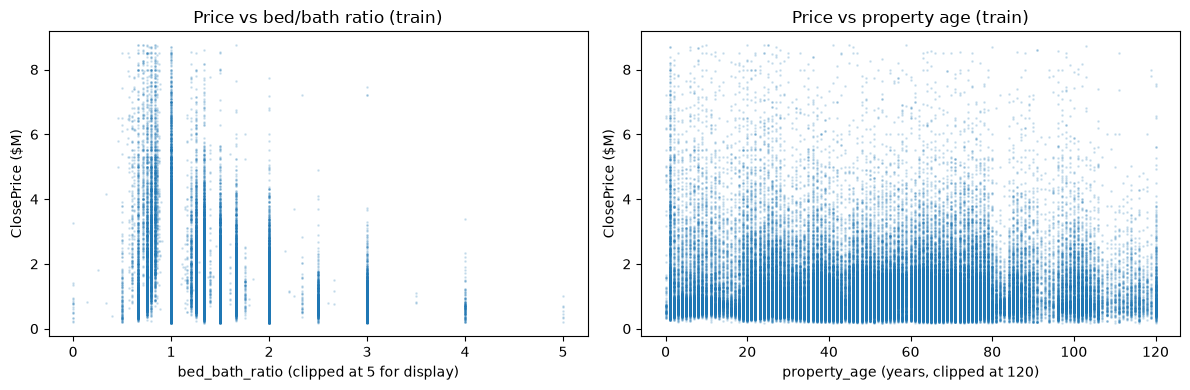

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(tr['bed_bath_ratio'].clip(upper=5), tr['ClosePrice'] / 1e6, s=1, alpha=0.15)
ax[0].set_xlabel('bed_bath_ratio (clipped at 5 for display)'); ax[0].set_ylabel('ClosePrice ($M)')
ax[0].set_title('Price vs bed/bath ratio (train)')
ax[1].scatter(tr['property_age'].clip(upper=120), tr['ClosePrice'] / 1e6, s=1, alpha=0.15)
ax[1].set_xlabel('property_age (years, clipped at 120)'); ax[1].set_ylabel('ClosePrice ($M)')
ax[1].set_title('Price vs property age (train)')
plt.tight_layout(); plt.show()

## 2. School-district layer — spatial join on lat/lon

**Source:** CA School District Areas 2024–25, California Department of Education via data.ca.gov
. The notebook downloads the GeoJSON automatically; if the download fails it prints manual steps and continues without the district
feature, so the rest of the notebook still runs.

**Join key:** `DistrictName` (e.g. "Alameda Unified"). It is high-cardinality (~1,000 districts),
so it goes through the frequency encoder like the other high-cardinality categoricals.

**Known simplification — overlapping districts:** California has Unified districts (K–12) that
overlap Elementary + High districts covering the same ground, so one property can fall inside
several polygons. This notebook keeps **one** district per property, preferring Unified, then the
alphabetically first name — and reports the multi-match rate. A two-feature split
(`elementary_district` + `high_district`) is a possible Week 7 refinement, not done here.

**Coordinate hygiene:** Week 3 already set invalid coordinates to NaN (Latitude == 0,
Longitude > 0). Those rows get no district and are handled by the pipeline's most-frequent
imputation, exactly like any other missing categorical.

In [4]:
# 2a. Fetch the boundary file (cached under data/ so re-runs are free)
import urllib.request

DISTRICT_GEOJSON_URL = ('https://gis.data.ca.gov/api/download/v1/items/'
                        'b0e3b936426a47ce9d9a2e77e2bb86cc/geojson?layers=0') 
DISTRICT_FILE = Path('data') / 'ca_school_districts_2024_25.geojson'

try:
    import geopandas as gpd
    HAVE_GPD = True
except ImportError:
    HAVE_GPD = False
    print('geopandas NOT installed -> district join skipped. Install with: pip install geopandas')
    print('Then re-run from this cell. Everything after §2 still works without the district feature.')

districts = None
if HAVE_GPD:
    if DISTRICT_FILE.exists():
        print(f'loading cached boundaries: {DISTRICT_FILE}')
        districts = gpd.read_file(DISTRICT_FILE)
    else:
        try:
            DISTRICT_FILE.parent.mkdir(exist_ok=True)
            print(f'downloading boundaries (one-time, ~tens of MB) ...')
            urllib.request.urlretrieve(DISTRICT_GEOJSON_URL, DISTRICT_FILE)
            districts = gpd.read_file(DISTRICT_FILE)
            print(f'downloaded -> {DISTRICT_FILE}')
        except Exception as e:
            print(f'download failed ({type(e).__name__}: {e})')
            print('Manual fallback: open https://data.ca.gov/dataset/california-school-district-areas-2024-25')
            print('  -> download the GeoJSON, save it as data/ca_school_districts_2024_25.geojson, re-run.')
            districts = None

if districts is not None:
    districts = districts.to_crs('EPSG:4326')
    print(f'boundaries: {len(districts)} districts | columns: '
          f'{[c for c in ["DistrictName", "DistrictType", "CDSCode", "CountyName"] if c in districts.columns]}')
    print(districts['DistrictType'].value_counts().to_string() if 'DistrictType' in districts.columns else '')
    DISTRICT_OK = True
else:
    DISTRICT_OK = False
    print('DISTRICT_OK = False -> continuing with bed_bath_ratio + property_age only.')

loading cached boundaries: data/ca_school_districts_2024_25.geojson
boundaries: 937 districts | columns: ['DistrictName', 'DistrictType', 'CDSCode', 'CountyName']
DistrictType
Elementary    516
Unified       345
High           76


In [5]:
# 2b. Spatial join: one district per property (Unified preferred on overlaps)
if DISTRICT_OK:
    from shapely.geometry import Point
    # DistrictType may be absent in some downloads — fall back to alphabetical-first dedup
    join_cols = ['DistrictName', 'geometry'] + (['DistrictType'] if 'DistrictType' in districts.columns else [])
    TYPE_RANK = {'Unified': 0, 'Elementary': 1, 'High': 2}   # overlap tie-break order

    for name, df in clean.items():
        pts = gpd.GeoDataFrame(
            df[['Longitude', 'Latitude']].copy(),
            geometry=[Point(xy) if pd.notna(xy[0]) and pd.notna(xy[1]) else None
                      for xy in zip(df['Longitude'], df['Latitude'])],
            crs='EPSG:4326')
        pts.index = df.index
        joined = gpd.sjoin(pts, districts[join_cols], how='left', predicate='within')
        # Multi-match report (before dedup)
        n_multi = int((joined.groupby(level=0).size() > 1).sum()) if len(joined) else 0
        if 'DistrictType' in joined.columns:
            joined['_rank'] = joined['DistrictType'].map(TYPE_RANK).fillna(9)
        else:
            joined['_rank'] = 9
        joined = joined.sort_values(['_rank', 'DistrictName'])
        joined = joined[~joined.index.duplicated(keep='first')]     # one row per property
        df['DistrictName'] = joined['DistrictName']
        matched = int(df['DistrictName'].notna().sum())
        print(f'{name}: matched {matched:,}/{len(df):,} ({matched / len(df):.1%}) | '
              f'multi-polygon properties (deduped): {n_multi:,} | '
              f'unmatched (NaN coords or outside boundaries): {len(df) - matched:,}')
    print('\nTop 10 districts (train):')
    print(clean['train']['DistrictName'].value_counts().head(10).to_string())
    print(f"\nDistrict cardinality (train): {clean['train']['DistrictName'].nunique()} unique values")
else:
    print('District join skipped (see §2a). New features this run: bed_bath_ratio, property_age.')

train: matched 105,869/105,974 (99.9%) | multi-polygon properties (deduped): 25,902 | unmatched (NaN coords or outside boundaries): 105
val: matched 11,343/11,416 (99.4%) | multi-polygon properties (deduped): 2,779 | unmatched (NaN coords or outside boundaries): 73
test: matched 12,257/12,339 (99.3%) | multi-polygon properties (deduped): 3,061 | unmatched (NaN coords or outside boundaries): 82

Top 10 districts (train):
DistrictName
Los Angeles Unified     10624
San Diego Unified        2847
Capistrano Unified       1870
Desert Sands Unified     1830
Palm Springs Unified     1665
Oakland Unified          1372
Long Beach Unified       1350
Corona-Norco Unified     1336
Hemet Unified            1292
Riverside Unified        1277

District cardinality (train): 612 unique values


## 3. Re-encode with the Week 3 recipe (fit on train only)

The exact Week 3 pipeline, rebuilt so the two new numerics (and `DistrictName`, if the join
succeeded) get identical treatment: numerics → median impute + StandardScaler, low-cardinality
categoricals → most-frequent impute + one-hot (`min_frequency=0.01`), high-cardinality
categoricals → most-frequent impute + frequency encoding. `FrequencyEncoder` is copied verbatim
from Week 3 (it must be defined in this notebook — it is a custom class).

Two checks after fitting: (1) the new feature list must contain **all 41 old features**
(same data, same recipe — the old encoding must reproduce exactly); (2) shapes and residual NaNs.

In [6]:
from sklearn.base import BaseEstimator, TransformerMixin

class FrequencyEncoder(BaseEstimator, TransformerMixin):
    """Simple leakage-free encoding for high-cardinality cats (fit sees train only)."""
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.cols_ = list(X.columns)
        self.maps_ = {c: X[c].value_counts(normalize=True) for c in self.cols_}
        return self
    def transform(self, X):
        X = pd.DataFrame(X, columns=self.cols_)
        out = pd.DataFrame(index=X.index)
        for c in self.cols_:
            out[c] = X[c].map(self.maps_[c]).fillna(0.0)
        return out.values
    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            input_features = getattr(self, 'cols_', [])
        return np.asarray(list(input_features))

HELPER = ['CloseMonth', '__source_file', 'CloseDate']
NEW_FEATURES = ['bed_bath_ratio', 'property_age'] + (['DistrictName'] if DISTRICT_OK else [])

X_new = {}
y_new = {}
for name, df in clean.items():
    y_new[name] = df['ClosePrice'].values
    X_new[name] = df.drop(columns=['ClosePrice', '__split'], errors='ignore')

tr_n = X_new['train']
feat_cols = [c for c in tr_n.columns if c not in HELPER]
for c in ['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet', 'YearBuilt',
          'Stories', 'ParkingTotal', 'GarageSpaces', 'MainLevelBedrooms', 'AssociationFee',
          'Latitude', 'Longitude', 'bed_bath_ratio', 'property_age']:
    if c in tr_n.columns:
        for Xn in X_new.values():
            Xn[c] = pd.to_numeric(Xn[c], errors='coerce')
numeric_cols = tr_n[feat_cols].select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in feat_cols if c not in numeric_cols]
LOW = [c for c in cat_cols if tr_n[c].nunique() < 50]
HIGH = [c for c in cat_cols if c not in LOW]
print(f'Numeric ({len(numeric_cols)}):', numeric_cols)
print('Low-cardinality (one-hot):', LOW)
print('High-cardinality (frequency):', HIGH)

FLAG_MISS_TH = 0.01
FLAG_COLS = [c for c in numeric_cols if tr_n[c].isna().mean() > FLAG_MISS_TH]
print('Missing indicators (>1% missing in train):', [f'{c}_was_missing' for c in FLAG_COLS])
for c in FLAG_COLS:
    for Xn in X_new.values():
        Xn[f'{c}_was_missing'] = Xn[c].isna().astype(int)
num_final = numeric_cols

preprocess_v2 = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_final),
    ('lowcard', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                         ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=0.01, sparse_output=False))]), LOW),
    ('highcard', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('freq', FrequencyEncoder())]), HIGH),
], remainder='drop', verbose_feature_names_out=False)

Xtr = preprocess_v2.fit_transform(X_new['train'])   # fit on train ONLY
Xva = preprocess_v2.transform(X_new['val'])
Xte = preprocess_v2.transform(X_new['test'])
new_features = list(preprocess_v2.get_feature_names_out())
print(f'\nEncoded shapes: train {Xtr.shape} / val {Xva.shape} / test {Xte.shape}')
print('Residual NaNs:', int(np.isnan(Xtr).sum() + np.isnan(Xva).sum() + np.isnan(Xte).sum()))
print(f'New feature count: {len(new_features)} (old: {len(old_features)}, new columns added: {NEW_FEATURES})')

missing_old = [f for f in old_features if f not in new_features]
print(f'Old features preserved: {len(old_features) - len(missing_old)}/{len(old_features)}'
      + ('' if not missing_old else f' | MISSING: {missing_old}'))
assert Xtr.shape[1] == Xva.shape[1] == Xte.shape[1] == len(new_features)
assert len(y_new['train']) == len(Xtr) and len(y_new['val']) == len(Xva) and len(y_new['test']) == len(Xte)
assert not np.isnan(Xtr).any() and not np.isnan(Xte).any(), 'Unexpected NaNs'

Numeric (20): ['Latitude', 'Longitude', 'LivingArea', 'ParkingTotal', 'YearBuilt', 'StreetNumberNumeric', 'BathroomsTotalInteger', 'BedroomsTotal', 'Stories', 'MainLevelBedrooms', 'GarageSpaces', 'AssociationFee', 'LotSizeSquareFeet', 'Stories_was_missing', 'MainLevelBedrooms_was_missing', 'GarageSpaces_was_missing', 'AssociationFee_was_missing', 'LotSizeSquareFeet_was_missing', 'bed_bath_ratio', 'property_age']
Low-cardinality (one-hot): ['ViewYN', 'PoolPrivateYN', 'AttachedGarageYN', 'StateOrProvince', 'FireplaceYN', 'Levels', 'NewConstructionYN']
High-cardinality (frequency): ['Flooring', 'MLSAreaMajor', 'CountyOrParish', 'City', 'HighSchoolDistrict', 'PostalCode', 'DistrictName']
Missing indicators (>1% missing in train): ['Stories_was_missing', 'MainLevelBedrooms_was_missing', 'GarageSpaces_was_missing', 'AssociationFee_was_missing', 'LotSizeSquareFeet_was_missing']

Encoded shapes: train (105974, 44) / val (11416, 44) / test (12339, 44)
Residual NaNs: 0
New feature count: 44 (old

## 4. Re-train on the new feature set

- **LR (new):** Linear Regression on the full new set — the linear model's answer to "do the new
  features help?"
- **LR (33 + new):** Linear Regression on the 33 Week 4 selected features PLUS the new features —
  the clean addition-only comparison for linear (same 33 base, only new columns added).
- **RF (new):** Random Forest with the Week 5 champion config. Week 5's tuning re-selected the
  default, so the champion config is simply 200 trees with default depth/leaf settings.
- **Old references:** LR (33 feats) is refit on the old matrices (seconds — verifies the frozen
  0.5570); RF (41 feats) is **loaded** from `output_week5/rf_tuned_41f.joblib` and only used to
  predict, so this notebook does not pay for a second 200-tree fit. If the file is missing, the
  frozen Week 5 test numbers are used instead.

In [7]:
# 4a. LR old (33 feats) — refit on old matrices to verify the frozen baseline
WEEK4_DIR = Path('output_week4')
sel_path = WEEK4_DIR / 'selected_features.csv'
selected = pd.read_csv(sel_path)['feature'].tolist() if sel_path.exists() else None
if selected is None:
    DROPPED_8 = ['LotSizeSquareFeet', 'LotSizeSquareFeet_was_missing', 'ParkingTotal',
                 'PoolPrivateYN_False', 'PoolPrivateYN_True',
                 'StateOrProvince_CA', 'StateOrProvince_infrequent_sklearn',
                 'Levels_infrequent_sklearn']
    selected = [f for f in old_features if f not in DROPPED_8]
sel_idx = [old_features.index(f) for f in selected]
lr_old = LinearRegression().fit(X_train_old[:, sel_idx], y_train)
for split, X, y in [('train', X_train_old[:, sel_idx], y_train),
                    ('val', X_val_old[:, sel_idx], y_val),
                    ('test', X_test_old[:, sel_idx], y_test)]:
    record('LR (33 feats, old)', split, y, lr_old.predict(X))

# 4b. LR new (full new set)
lr_new = LinearRegression().fit(Xtr, y_train)
for split, X, y in [('train', Xtr, y_train), ('val', Xva, y_val), ('test', Xte, y_test)]:
    record('LR (new feats)', split, y, lr_new.predict(X))

# 4b2. LR (33 + new) — clean addition-only comparison for linear: same 33 base as Week 4,
# only the new columns added (no re-added dropped features to confound the comparison)
sel_new_idx = ([new_features.index(f) for f in selected if f in new_features]
               + [new_features.index(f) for f in NEW_FEATURES if f in new_features])
lr_33new = LinearRegression().fit(Xtr[:, sel_new_idx], y_train)
for split, X, y in [('train', Xtr[:, sel_new_idx], y_train),
                    ('val', Xva[:, sel_new_idx], y_val),
                    ('test', Xte[:, sel_new_idx], y_test)]:
    record('LR (33 + new feats)', split, y, lr_33new.predict(X))
print('LR old vs new (test):')
print(pd.DataFrame(rows).query("split == 'test'").set_index('model').round(4).to_string())

# 4c. RF old (41 feats) — load champion, predict only
rf_old_pred = None
rf_old_path = WEEK5_DIR / 'rf_tuned_41f.joblib'
if rf_old_path.exists():
    rf_old = joblib.load(rf_old_path)
    rf_old_pred = rf_old.predict(X_test_old)
    record('RF (41 feats, old)', 'test', y_test, rf_old_pred)
    print('\nRF old (41 feats) — test (from saved champion):',
          {k: round(v, 4) for k, v in metrics(y_test, rf_old_pred).items()})
else:
    print('\noutput_week5/rf_tuned_41f.joblib not found — using frozen Week 5 numbers for RF old:')
    print('test R2 = 0.8612, RMSE = 369981, MAE = 180129, MAPE = 13.76')
    rows.append({'model': 'RF (41 feats, old)', 'split': 'test',
                 'R2': 0.8612, 'RMSE': 369981.0, 'MAE': 180129.0, 'MAPE': 13.76})

LR old vs new (test):
                    split      R2         RMSE          MAE     MAPE
model                                                               
LR (33 feats, old)   test  0.5570  661068.2231  419193.6546  40.6691
LR (new feats)       test  0.5617  657513.8181  414106.0474  39.8645
LR (33 + new feats)  test  0.5618  657502.9637  414112.2033  39.8600

RF old (41 feats) — test (from saved champion): {'R2': 0.8612, 'RMSE': 369981.2539, 'MAE': 180128.5227, 'MAPE': 13.7609}


In [8]:
# 4d. RF new (full new set) — champion config, 200 trees
t0 = time.time()
rf_new = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf_new.fit(Xtr, y_train)
print(f'RF new fit time: {time.time() - t0:.1f}s')
pred_new = rf_new.predict(Xte)
for split, X, y in [('train', Xtr, y_train), ('val', Xva, y_val), ('test', Xte, y_test)]:
    record('RF (new feats)', split, y, rf_new.predict(X))
print('RF new — test:', {k: round(v, 4) for k, v in metrics(y_test, pred_new).items()})

RF new fit time: 14.3s
RF new — test: {'R2': 0.8617, 'RMSE': 369380.258, 'MAE': 179842.8192, 'MAPE': 13.7617}


## 5. Comparison — old vs new feature sets (the handbook deliverable)

Read the test columns: bed/bath ratio, property age, and the district layer moved the needle only slightly. RF improved by just +0.0005 in test R² (0.8612 → 0.8617), as expected — the forest already had the raw ingredients (beds, baths, YearBuilt, lat/lon), so the engineered features mostly repackage information it could already split on. LR improved a little more (+0.0048, 0.5570 → 0.5618 for the 33 + new set), consistent with linear models being unable to invent ratios or age gaps on their own — but even that gain is small, so the new features help linear models modestly rather than transforming them. The district join itself succeeded (99.9% of train, 99.4% of val, 99.3% of test matched), so the small gain is not a join failure.


In [9]:
comp = pd.DataFrame(rows)
order = ['LR (33 feats, old)', 'LR (33 + new feats)', 'LR (new feats)',
         'RF (41 feats, old)', 'RF (new feats)']
comp['model'] = pd.Categorical(comp['model'], categories=order, ordered=True)
test_tbl = comp[comp['split'] == 'test'].sort_values('model').set_index('model')
val_r2 = comp[comp['split'] == 'val'].set_index('model')['R2'].rename('val_R2')
test_tbl = test_tbl.join(val_r2)[['val_R2', 'R2', 'RMSE', 'MAE', 'MAPE']]
test_tbl.columns = ['val_R2', 'test_R2', 'test_RMSE', 'test_MAE', 'test_MAPE']
test_tbl['val_R2'] = test_tbl['val_R2'].apply(lambda v: '/' if pd.isna(v) else round(float(v), 4))
test_tbl['n_features'] = test_tbl.index.map({'LR (33 feats, old)': 33,
                                             'LR (33 + new feats)': len(sel_new_idx),
                                             'LR (new feats)': len(new_features),
                                             'RF (41 feats, old)': 41,
                                             'RF (new feats)': len(new_features)})
test_tbl = test_tbl[['n_features', 'val_R2', 'test_R2', 'test_RMSE', 'test_MAE', 'test_MAPE']]
for c in ['test_R2', 'test_RMSE', 'test_MAE', 'test_MAPE']:
    test_tbl[c] = test_tbl[c].round(4)
print(test_tbl.to_string())
test_tbl.to_csv(OUT_DIR / 'feature_set_comparison.csv')
print(f'\nsaved -> {OUT_DIR / "feature_set_comparison.csv"}')
print(f'\nNew columns in this run: {NEW_FEATURES} (district join: {"OK" if DISTRICT_OK else "skipped"})')

                     n_features  val_R2  test_R2    test_RMSE     test_MAE  test_MAPE
model                                                                                
LR (33 feats, old)           33  0.5447   0.5570  661068.2231  419193.6546    40.6691
LR (33 + new feats)          36  0.5496   0.5618  657502.9637  414112.2033    39.8600
LR (new feats)               44  0.5495   0.5617  657513.8181  414106.0474    39.8645
RF (41 feats, old)           41       /   0.8612  369981.2539  180128.5227    13.7609
RF (new feats)               44  0.8661   0.8617  369380.2580  179842.8192    13.7617

saved -> output_week6/feature_set_comparison.csv

New columns in this run: ['bed_bath_ratio', 'property_age', 'DistrictName'] (district join: OK)


### 5b. Where do the new features rank in the forest?

If `bed_bath_ratio` / `property_age` / `DistrictName` land near the top, the engineering added
real signal. If they land near the bottom, the forest was already getting that information from
the raw columns — still a useful negative result for the write-up.

In [10]:
imp_new = pd.Series(rf_new.feature_importances_, index=new_features).sort_values(ascending=False)
print('Top 15 — RF (new feats):')
print(imp_new.head(15).round(4).to_string())
print('\nNew-feature ranks:')
for f in NEW_FEATURES:
    if f in imp_new.index:
        rank = int((imp_new.index == f).argmax()) + 1
        print(f'  {f}: rank {rank}/{len(imp_new)}, importance {imp_new[f]:.4f}')
    else:
        print(f'  {f}: not in feature list (check §3 routing)')
print('\nTop 15 — RF (new feats) vs Week 5 top features (BathroomsTotalInteger was #1 at 0.238):')
print('Week 5 location block (lat/lon/county/city/postal) was ~0.34 combined — see if DistrictName')
print('absorbs part of that block in the new ranking.')

Top 15 — RF (new feats):
BathroomsTotalInteger    0.2354
LivingArea               0.1886
Longitude                0.1135
Latitude                 0.0994
CountyOrParish           0.0604
PostalCode               0.0573
StreetNumberNumeric      0.0270
LotSizeSquareFeet        0.0254
City                     0.0234
DistrictName             0.0203
MLSAreaMajor             0.0179
Stories_was_missing      0.0166
YearBuilt                0.0158
property_age             0.0157
bed_bath_ratio           0.0120

New-feature ranks:
  bed_bath_ratio: rank 15/44, importance 0.0120
  property_age: rank 14/44, importance 0.0157
  DistrictName: rank 10/44, importance 0.0203

Top 15 — RF (new feats) vs Week 5 top features (BathroomsTotalInteger was #1 at 0.238):
Week 5 location block (lat/lon/county/city/postal) was ~0.34 combined — see if DistrictName
absorbs part of that block in the new ranking.


district layer adds a mid-tier location signal, partially overlapping existing location features

YearBuilt 0.0158 + property_age 0.0157 = 0.0315 (compare YearBuilt 0.0334 last week week5)

## 6. Diagnostics — new champion vs Week 5 champion

Same three checks as Week 5 section6, so the numbers are directly comparable: median residual
(unbiased ≈ 0), luxury-band (>$2M) underprediction, and the ±10% hit rate.

In [11]:
resid_new = y_test - pred_new
lux = y_test > 2_000_000
hit_new = np.mean(np.abs(resid_new) <= 0.10 * y_test) * 100
print(f'RF (new feats) — median residual: ${np.median(resid_new):,.0f} (negative = overprediction)')
print(f'  luxury (>$2M, {lux.mean():.1%} of test): mean residual ${np.mean(resid_new[lux]):,.0f} '
      f'({np.mean(resid_new[lux] / y_test[lux]) * 100:.1f}% of actual)')
print(f'  ±10% hit rate: {hit_new:.1f}%')
print('\nWeek 5 champion (RF 41 feats) for comparison: median residual +$2,478; '
      'luxury underpredicted ~10% (~$332k); hit rate 56.6%.')
if rf_old_pred is not None:
    resid_old = y_test - rf_old_pred
    hit_old = np.mean(np.abs(resid_old) <= 0.10 * y_test) * 100
    print(f'RF (41 feats, old) re-scored here: median residual ${np.median(resid_old):,.0f}; '
          f'hit rate {hit_old:.1f}%')

RF (new feats) — median residual: $2,161 (negative = overprediction)
  luxury (>$2M, 13.6% of test): mean residual $323,692 (7.6% of actual)
  ±10% hit rate: 56.8%

Week 5 champion (RF 41 feats) for comparison: median residual +$2,478; luxury underpredicted ~10% (~$332k); hit rate 56.6%.
RF (41 feats, old) re-scored here: median residual $2,478; hit rate 56.6%


## 7. Bonus — log-target head-to-head (Linear Regression only)

**Why:** Week 5's diagnostics showed right-skew, a luxury ceiling, and funnel heteroskedasticity —
exactly what a log target compresses. A classmate's `log_price` model reportedly beats the linear
baseline; this section tests that claim on the *same* new feature set, so only the target changes.

**Back-transform, two ways:** naive `exp(pred_log)` underestimates (Jensen's inequality — the
mean of the log is not the log of the mean). The corrected version adds half the log-space
residual variance: `exp(pred_log + σ²/2)`, σ² estimated on train residuals. **All metrics are
reported in dollars**, so they compare directly with the linear rows above and with the 0.8612
champion. RF-on-log is left for Week 7 (forests are already scale-robust; the gain, if any,
should be small — worth one run alongside GBM tuning).

In [12]:
y_log_train = np.log(y_train)
lr_log = LinearRegression().fit(Xtr, y_log_train)
pred_log = lr_log.predict(Xte)
resid_log_train = y_log_train - lr_log.predict(Xtr)
sigma2 = float(np.var(resid_log_train))
pred_naive = np.exp(pred_log)
pred_jensen = np.exp(pred_log + sigma2 / 2)
print(f'log-space residual variance (train): sigma^2 = {sigma2:.4f} '
      f'(mean correction factor exp(sigma^2/2) = {np.exp(sigma2 / 2):.4f})')
print('\nLog-target LR (new feats), scored in dollars:')
for name, p in [('LR log-target, naive exp', pred_naive),
                ('LR log-target, Jensen-corrected', pred_jensen)]:
    m = metrics(y_test, p)
    print(f'  {name}: R2 = {m["R2"]:.4f}, RMSE = ${m["RMSE"]:,.0f}, '
          f'MAE = ${m["MAE"]:,.0f}, MAPE = {m["MAPE"]:.2f}%')
    rows.append({'model': name, 'split': 'test', **m})
lin_new_test = [r for r in rows if r['model'] == 'LR (new feats)' and r['split'] == 'test'][0]
print(f'\nLinear LR (new feats) for reference: R2 = {lin_new_test["R2"]:.4f}, '
      f'RMSE = ${lin_new_test["RMSE"]:,.0f}, MAPE = {lin_new_test["MAPE"]:.2f}%')

log-space residual variance (train): sigma^2 = 0.1611 (mean correction factor exp(sigma^2/2) = 1.0839)

Log-target LR (new feats), scored in dollars:
  LR log-target, naive exp: R2 = -0.3666, RMSE = $1,161,063, MAE = $414,397, MAPE = 32.67%
  LR log-target, Jensen-corrected: R2 = -0.5316, RMSE = $1,229,153, MAE = $418,861, MAPE = 35.84%

Linear LR (new feats) for reference: R2 = 0.5617, RMSE = $657,514, MAPE = 39.86%


In [13]:
# section 7 sanity check 
y_log_test = np.log(y_test)
resid_log_test = y_log_test - pred_log
print(f'log-space test R2: {r2_score(y_log_test, pred_log):.4f}')
print(f'log-space residual variance: train {sigma2:.4f} vs test {float(np.var(resid_log_test)):.4f}')
print(f'mean log residual (test): {float(np.mean(resid_log_test)):.4f}  (0 = unbiased in log space)')

chk = pd.DataFrame({
    'actual': y_test,
    'pred_naive': pred_naive,
    'residual': y_test - pred_naive,
})
chk['abs_error'] = chk['residual'].abs()
chk['pct_error'] = chk['residual'] / chk['actual'] * 100
chk = chk.sort_values('abs_error', ascending=False)

sse_total = float((chk['residual'] ** 2).sum())
print('\nTop 10 largest dollar errors (naive exp):')
print(chk.head(10).to_string(index=False))
print(f'\nTop 10 share of total SSE: {float((chk.head(10)["residual"] ** 2).sum()) / sse_total:.1%}')
print(f'Top 100 share of total SSE: {float((chk.head(100)["residual"] ** 2).sum()) / sse_total:.1%}')
lux = chk[chk['actual'] > 2_000_000]
print(f'Luxury (>$2M) share of SSE: {float((lux["residual"] ** 2).sum()) / sse_total:.1%} '
      f'({len(lux)} / {len(chk)} properties)')
print(f'Luxury mean residual: ${lux["residual"].mean():,.0f}')


log-space test R2: 0.5801
log-space residual variance: train 0.1611 vs test 0.1743
mean log residual (test): 0.0207  (0 = unbiased in log space)

Top 10 largest dollar errors (naive exp):
   actual   pred_naive      residual    abs_error    pct_error
6835000.0 9.849240e+07 -9.165740e+07 9.165740e+07 -1341.000732
7400000.0 3.670643e+07 -2.930643e+07 2.930643e+07  -396.032796
4040000.0 2.690964e+07 -2.286964e+07 2.286964e+07  -566.080141
7600000.0 2.240641e+07 -1.480641e+07 1.480641e+07  -194.821152
5995999.0 1.793206e+07 -1.193606e+07 1.193606e+07  -199.067034
7400000.0 1.932901e+07 -1.192901e+07 1.192901e+07  -161.202776
1550000.0 1.269819e+07 -1.114819e+07 1.114819e+07  -719.237960
4000000.0 1.378687e+07 -9.786869e+06 9.786869e+06  -244.671734
2565000.0 1.154280e+07 -8.977801e+06 8.977801e+06  -350.011723
7130000.0 1.490082e+07 -7.770819e+06 7.770819e+06  -108.987645

Top 10 share of total SSE: 64.0%
Top 100 share of total SSE: 75.1%
Luxury (>$2M) share of SSE: 91.3% (1674 / 12339 pro

## 8. Save artifacts + summary

In [14]:
# New encoded matrices + pipeline + feature list (same layout as Week 3 section9)
np.save(OUT_DIR / 'X_train_enc_v2.npy', Xtr); np.save(OUT_DIR / 'X_val_enc_v2.npy', Xva)
np.save(OUT_DIR / 'X_test_enc_v2.npy', Xte)
joblib.dump(preprocess_v2, OUT_DIR / 'preprocessing_pipeline_v2.joblib')
pd.Series(new_features).to_csv(OUT_DIR / 'feature_list_v2.csv', index=False, header=['feature'])
# New cleaned frames (with engineered columns) for inspection / Week 7
for name, df in clean.items():
    out = df.copy()
    out.to_csv(OUT_DIR / f'cleaned_{name}_v2.csv', index=False)
    print(f'cleaned_{name}_v2.csv:', out.shape)
# New champion: predictions always; the full model dump is slow + GB-scale (same as Week 5),
np.save(OUT_DIR / 'rf_new_test_pred.npy', pred_new)
joblib.dump(rf_new, OUT_DIR / 'rf_new.joblib')

final = pd.DataFrame(rows)
final_test = final[final['split'] == 'test'].set_index('model').round(4)
summary = [
    'Week 6 — Feature Engineering (California close-price prediction)',
    f'Date: {pd.Timestamp.now().date()}',
    f'New features: {NEW_FEATURES} (district join: {"OK" if DISTRICT_OK else "skipped — see §2a"})',
    f'Feature counts: old 41 -> new {len(new_features)}',
    f'Rows: train {len(y_train):,} / val {len(y_val):,} / test {len(y_test):,}',
    '',
    final_test.to_string(),
    '',
    'Champion going into Week 7: RF on the new feature set (200 trees, Week 5 champion config).',
    'Note: the old-vs-new RF gap is the honest price of the engineered features; a small gap',
    'is expected because the forest already had beds, baths, YearBuilt and lat/lon to split on.',
]
(OUT_DIR / 'week6_summary.txt').write_text('\n'.join(summary))
print('\n'.join(summary))
print(f'\nsaved -> {OUT_DIR}/ (matrices, pipeline, feature list, comparison table, summary)')

cleaned_train_v2.csv: (105974, 39)
cleaned_val_v2.csv: (11416, 39)
cleaned_test_v2.csv: (12339, 39)
Week 6 — Feature Engineering (California close-price prediction)
Date: 2026-10-25
New features: ['bed_bath_ratio', 'property_age', 'DistrictName'] (district join: OK)
Feature counts: old 41 -> new 44
Rows: train 105,974 / val 11,416 / test 12,339

                                split      R2          RMSE          MAE     MAPE
model                                                                            
LR (33 feats, old)               test  0.5570  6.610682e+05  419193.6546  40.6691
LR (new feats)                   test  0.5617  6.575138e+05  414106.0474  39.8645
LR (33 + new feats)              test  0.5618  6.575030e+05  414112.2033  39.8600
RF (41 feats, old)               test  0.8612  3.699813e+05  180128.5227  13.7609
RF (new feats)                   test  0.8617  3.693803e+05  179842.8192  13.7617
LR log-target, naive exp         test -0.3666  1.161063e+06  414396.5930  32.6

## 9. What's next — Week 7: Advanced Models

- **Gradient Boosting (XGBoost / LightGBM)** on the new feature set — the handbook's Week 7
  deliverable (`05_advanced_models.ipynb` in the handbook's numbering; this notebook took the
  `05_` slot in my local sequence, so Week 7's file will need a fresh number, e.g.
  `06_advanced_models.ipynb`).
- Light tuning: depth, learning rate, `n_estimators` — tuned on validation only, test once.
